# Louisiana LWI EnDMC: Public Catalog, Cloud Raster Reads, and Selective Download

This notebook uses `LouisianaEndmc` to work with the Louisiana Watershed Initiative (LWI)
[Environmental Data and Model Catalog](https://lwi.endmc.org) (EnDMC), operated by The Water Institute.
EnDMC publishes HEC-RAS, HEC-HMS, HEC-FIA, and Go-Consequences model applications and supporting
datasets. Every published file is in the public S3 bucket `lwi-model-data`.

No account or credentials are used. The catalog comes from the public search endpoint that the EnDMC
search page itself calls; files come from anonymous S3 listing and HTTP range requests.

**What this notebook does**

1. Reads the live catalog and compares it with the bundled offline snapshot.
2. Filters resources by LWI region and software.
3. Reads one resource's public metadata page.
4. Lists one model's files and summarizes them by component.
5. Reads a window of an online depth raster through GDAL `/vsicurl/` without downloading the file.
6. Downloads a few megabytes of HEC-RAS project text files with a receipt and checksum verification.

**Requirements**: internet access; `rasterio` and `matplotlib` for section 5; the optional `awscrt`
package only when verifying CRC64NVME checksums. HEC-RAS is not required. Total network transfer is
a few tens of megabytes. Downloads go to the repository's ignored `working/` folder.

See the [Louisiana Watershed Initiative EnDMC user guide](https://rascommander.info/ras/user-guide/louisiana-endmc/)
for the full API and data notes.

In [1]:
from pathlib import Path
import os
import sys

try:
    from ras_commander.sources.state import LouisianaEndmc
except ImportError:
    parent_directory = Path.cwd()
    if parent_directory.name == "examples":
        parent_directory = parent_directory.parent
    sys.path.append(str(parent_directory))
    from ras_commander.sources.state import LouisianaEndmc

import pandas as pd

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
WORK_DIR = REPO_ROOT / "working" / "932_endmc"   # ignored by .gitignore
WORK_DIR.mkdir(parents=True, exist_ok=True)

# Resources used below (public EnDMC ids)
ABBEVILLE_MODEL = "6a3d7158f74d9b1d5415493a"   # LWI Region 5 Vermilion - Abbeville Breakout HEC-RAS Model
TICKFAW_RASTERS = "69fc95b64c0345e94060a3bc"   # Region 7 Tickfaw Mosaiced Maximum Rasters

print("Working folder:", WORK_DIR.relative_to(REPO_ROOT).as_posix())

Working folder: working/932_endmc


## 1. Live catalog with snapshot fallback

`list_resources()` calls `GET https://lwi.endmc.org/search` with `Accept: application/json` and resolves
software through the same endpoint's filter (five requests in total, cached for the session). With the
default `source="auto"`, an unreachable site falls back to the dated snapshot bundled with the package.
`source="snapshot"` reads only the snapshot.

In [2]:
live = LouisianaEndmc.list_resources()
snapshot = LouisianaEndmc.list_resources(source="snapshot")

print(f"Live catalog:     {len(live)} resources (source: {', '.join(live['catalog_source'].unique())})")
print(f"Bundled snapshot: {len(snapshot)} resources (captured {snapshot.attrs['snapshot_captured']})")

new_ids = sorted(set(live["resource_id"]) - set(snapshot["resource_id"]))
print(f"Published after the snapshot: {len(new_ids)}")
display(live[live["resource_id"].isin(new_ids)][["resource_id", "kind", "title", "software"]])

summary = (
    live.assign(software=live["software"].fillna("(dataset)"))
    .groupby(["kind", "software"]).size().rename("resources").reset_index()
)
summary

Live catalog:     410 resources (source: live)
Bundled snapshot: 409 resources (captured 2026-11-09)
Published after the snapshot: 2


,resource_id,kind,title,software
164,69ff8e4705c44e05fa7df805,model_application,LWI Region 1 Lower Red-Lake Iatt HEC-FIA Model,HEC-FIA
284,6840bc5e66190e023393c032,model_application,Louisiana Watershed Initiative (LWI)-Region 6 (R6) West Central Louisiana Coastal (WCL...,HEC-RAS


,kind,software,resources
0,dataset,(dataset),44
1,model_application,Go Consequences,43
2,model_application,HEC-FIA,42
3,model_application,HEC-HMS,92
4,model_application,HEC-RAS,189


## 2. Filter by region and software

`region` is derived from titles and keywords (for example `"Region 5"`); a few statewide or pilot
resources have none. `software` is one of `HEC-RAS`, `HEC-HMS`, `HEC-FIA`, or `Go Consequences`.
`search=` passes a full-text query to the site.

In [3]:
by_region = pd.crosstab(live["region"].fillna("(none)"), live["software"].fillna("(dataset)"))
by_region

software,(dataset),Go Consequences,HEC-FIA,HEC-HMS,HEC-RAS
region,,,,,
(none),3,0,0,1,1
Region 1,21,10,10,11,11
Region 2,0,9,9,16,19
Region 3,0,5,5,4,11
Region 4,7,6,2,24,36
Region 5,4,5,5,16,59
Region 6,0,2,3,0,6
Region 7,8,5,7,18,38
Region 9,1,1,1,2,8


In [4]:
region5_ras = LouisianaEndmc.list_resources(software="HEC-RAS", region=5)
print(f"Region 5 HEC-RAS model applications: {len(region5_ras)}")
region5_ras[["resource_id", "title", "date"]].head(10)

Region 5 HEC-RAS model applications: 59


,resource_id,title,date
0,69c709ad83a457fec16538ce,LWI Region 5 Atchafalaya (Bayou Courtableau) Proof-of-Concept HEC-RAS Model,2022-11-01
1,6824fd4ba95cc87c1906192e,LWI Region 5 Atchafalaya - Atchafalaya River at Atchafalaya Floodway River Station 54 ...,2022-11-01
2,682638744988a119d9081c44,LWI Region 5 Atchafalaya - Atchafalaya River at Atchafalaya Floodway River Station 59 ...,2022-11-01
3,6827c4df4988a119d9082886,"LWI Region 5 Atchafalaya - Atchafalaya River at Simmesport, LA HEC-RAS Model",2022-11-01
4,6827c1a34988a119d90827ac,LWI Region 5 Atchafalaya - Bayour des Glaises HEC-RAS Model,2022-11-01
5,6827c8794988a119d9082941,LWI Region 5 Atchafalaya - Coastal Transition Zone HEC-RAS model,2022-11-01
6,682ca0b94988a119d90830ec,LWI Region 5 Atchafalaya - Johnson Bayou at Point Coupee Pump Station HEC-RAS Model,2022-11-01
7,682ca23ca95cc87c1906326c,LWI Region 5 Atchafalaya - Morganza Floodway at Atchafalaya Floodway HEC-RAS Model,2022-11-01
8,682ca3324988a119d9083193,LWI Region 5 Atchafalaya - Morganza Floodway at I-10 HEC-RAS Model,2022-11-01
9,682ca439a95cc87c190632ed,LWI Region 5 Atchafalaya - Morganza Floodway at US-190 HEC-RAS Model,2022-11-01


## 3. Public resource metadata

`get_resource_metadata()` parses the public resource page. It returns labelled fields such as the
application date, coordinate system, and software version, plus the containing package and the
associated simulations. Author and owner contact fields are omitted.

In [5]:
meta = LouisianaEndmc.get_resource_metadata(ABBEVILLE_MODEL)
print(meta["title"])
for field in ("Application date", "Common software version", "Coordinate system", "Dimension", "Access Level"):
    print(f"  {field:24s} {meta['fields'].get(field)}")
print("Containing package:", [p["title"] for p in meta["containing_packages"]])
print("Associated simulations:")
for sim in meta["associated_resources"]:
    print("  -", sim["title"])

LWI Region 5 Vermilion - Abbeville Breakout HEC-RAS Model
  Application date         2026-06-26
  Common software version  HEC-RAS version 6.4.1
  Coordinate system        EPSG:3452
  Dimension                2D
  Access Level             Public
Containing package: ['LWI Region 5 Vermilion Watershed']
Associated simulations:
  - LWI Region 5 Vermilion - Abbeville Breakout HEC-RAS Model: August 2016 Flood
  - LWI Region 5 Vermilion - Abbeville Breakout HEC-RAS Model: October 2015 Flood
  - LWI Region 5 Vermilion - Abbeville Breakout HEC-RAS Model: 10-year Design Storm
  - LWI Region 5 Vermilion - Abbeville Breakout HEC-RAS Model: 100-year Design Storm
  - LWI Region 5 Vermilion - Abbeville Breakout HEC-RAS Model: 500-year Design Storm


## 4. List a resource's files by component

`list_objects()` lists the resource prefix anonymously and classifies each object. Components separate
the HEC-RAS project text, geometry and plan HDF files, terrain, land cover, run artifacts, outputs,
DSS, GIS, and documents, so a download can take only what a task needs. Classification is a path
heuristic; review `other` rows before relying on a filter for completeness.

In [6]:
objects = LouisianaEndmc.list_objects(ABBEVILLE_MODEL)
by_component = (
    objects.groupby("component")["size"]
    .agg(files="count", gib=lambda s: round(s.sum() / 1024**3, 3))
    .sort_values("gib", ascending=False)
)
print(f"{len(objects)} objects, {objects['size'].sum() / 1024**3:.1f} GiB in {objects.attrs['s3_prefix']}")
by_component

394 objects, 53.9 GiB in endmc-managed/model_application/6a3d7158f74d9b1d5415493a/


,files,gib
component,,
terrain,11,38.092
plan_hdf,15,8.815
other,30,3.547
ras_run_artifact,148,2.089
dss,58,1.052
ras_project,24,0.140
land_cover,11,0.071
gis,93,0.066
geometry_hdf,3,0.020


In [7]:
print("Stored S3 checksum algorithms:", objects["checksum_algorithm"].value_counts(dropna=False).to_dict())
objects.loc[objects["component"] == "ras_project", ["relative_path", "size", "checksum_algorithm"]]

Stored S3 checksum algorithms: {'CRC32': 233, 'CRC64NVME': 161}


,relative_path,size,checksum_algorithm
28,_Abbeville/Backup.g01,4503773,CRC32
29,_Abbeville/Backup.p01,8136,CRC32
30,_Abbeville/Backup.u01,58336,CRC32
31,_Abbeville/Backup.u01.hdf,24600,CRC32
355,_Abbeville/VE_Abbeville.g01,764153,CRC32
357,_Abbeville/VE_Abbeville.g02,763082,CRC32
359,_Abbeville/VE_Abbeville.g08,763081,CRC32
367,_Abbeville/VE_Abbeville.p01,8120,CRC32
369,_Abbeville/VE_Abbeville.p02,8136,CRC32
371,_Abbeville/VE_Abbeville.p03,8136,CRC32


## 5. Read an online raster with `/vsicurl/`

`get_raster_urls()` returns HTTPS and GDAL `/vsicurl/` paths for a resource's Depth, WSE, and Velocity
rasters. GDAL fetches only the byte ranges it needs. The Tickfaw 100-year depth mosaic below is about
1.4 GB, tiled in 128 x 128 blocks without overviews, so reading one 2048 x 2048 window transfers only
the tiles that cover it.

In [8]:
os.environ.setdefault("GDAL_DISABLE_READDIR_ON_OPEN", "EMPTY_DIR")   # skip sidecar directory probes
os.environ.setdefault("CPL_VSIL_CURL_ALLOWED_EXTENSIONS", ".tif")

rasters = LouisianaEndmc.get_raster_urls(TICKFAW_RASTERS)
print(rasters["component"].value_counts().to_string())
depth_100 = rasters[
    (rasters["component"] == "output_depth") & rasters["relative_path"].str.contains("_100yr_")
].iloc[0]
print()
print(depth_100["relative_path"], f"({depth_100['size'] / 1024**3:.2f} GiB)")
print(depth_100["vsicurl"])

component
output_depth       16
output_velocity    16
output_wse         16

Depth/07_TI_99999_100yr_99999_99999_99999_V9A1_99999_99999_Depth.tif (1.34 GiB)
/vsicurl/https://lwi-model-data.s3.us-east-1.amazonaws.com/endmc-managed/dataset/69fc95b64c0345e94060a3bc/Depth/07_TI_99999_100yr_99999_99999_99999_V9A1_99999_99999_Depth.tif


In [9]:
import rasterio
from rasterio.windows import Window

with rasterio.open(depth_100["vsicurl"]) as src:
    print("CRS:        ", src.crs.to_string())
    print("Size:       ", src.width, "x", src.height, "pixels at", src.res, "(US survey feet)")
    print("Tiling:     ", src.block_shapes[0], "blocks,", src.profile.get("compress"), "compressed")
    print("Overviews:  ", src.overviews(1) or "none")
    print("Nodata:     ", src.nodata)

    window = Window(src.width // 2 - 1024, int(src.height * 0.6) - 1024, 2048, 2048)
    depth = src.read(1, window=window, masked=True)
    window_bounds = src.window_bounds(window)

print(f"Window: {depth.shape}, wet pixels {depth.count():,}, max depth {depth.max():.2f} ft, "
      f"mean wet depth {depth.mean():.2f} ft")

CRS:         EPSG:3452
Size:        39816 x 71698 pixels at (5.0, 5.0) (US survey feet)
Tiling:      (128, 128) blocks, lzw compressed
Overviews:   none
Nodata:      3.3999999521443642e+38


Window: (2048, 2048), wet pixels 4,085,796, max depth 22.01 ft, mean wet depth 5.64 ft


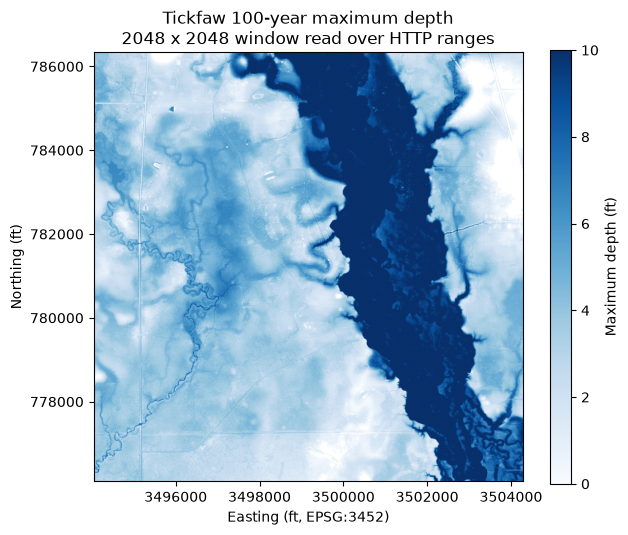

In [10]:
import matplotlib.pyplot as plt
import numpy as np

left, bottom, right, top = window_bounds
fig, ax = plt.subplots(figsize=(6.5, 6))
image = ax.imshow(depth.filled(np.nan), extent=(left, right, bottom, top), cmap="Blues", vmin=0, vmax=10)
fig.colorbar(image, ax=ax, label="Maximum depth (ft)", shrink=0.8)
ax.set_title("Tickfaw 100-year maximum depth\n2048 x 2048 window read over HTTP ranges")
ax.set_xlabel("Easting (ft, EPSG:3452)")
ax.set_ylabel("Northing (ft)")
ax.ticklabel_format(style="plain")
plt.tight_layout()
plt.show()

The mosaic stores nodata as about 3.4e38 (the float32 maximum). Reading with `masked=True` honors
the declared nodata; mask it explicitly if a reader ignores the declaration.

## 6. Selective download with a receipt and checksum verification

`download_resource()` downloads only the selected objects. Here `components=["ras_project"]` is
narrowed with globs to the Abbeville project, plan, geometry, unsteady-flow, and RAS Mapper text files
(about 3 MB). `dry_run=True` shows the plan first.

- Large files are fetched as parallel byte ranges (default four streams) and resume from `.part` state.
- Every file is checked against the listed size. `verify="checksum"` also compares the full-object
  checksum S3 stored at upload, using the algorithm the listing reports (these Abbeville files carry
  CRC32, verified with the standard library; newer uploads carry CRC64NVME, which needs `awscrt`).
- `max_path_length=240` (the default) refuses destinations that would leave no `MAX_PATH` headroom.
- A `_endmc_<resource_id>.json` receipt records each file.

In [11]:
DOWNLOAD_DIR = WORK_DIR / "abbeville"
project_text = ["*/VE_Abbeville.prj", "*/VE_Abbeville.p0?", "*/VE_Abbeville.g0?",
                "*/VE_Abbeville.u0?", "*/VE_Abbeville.rasmap"]

plan = LouisianaEndmc.download_resource(
    ABBEVILLE_MODEL, DOWNLOAD_DIR, components=["ras_project"], patterns=project_text, dry_run=True
)
print(f"Plan: {len(plan)} files, {plan.attrs['total_bytes'] / 1024**2:.2f} MiB")
plan[["relative_path", "size", "status"]]

2026-11-09 19:36:01 - ras_commander.sources.state.louisiana_endmc - INFO - EnDMC 6a3d7158f74d9b1d5415493a: 15 objects, 2.72 MiB selected


Plan: 15 files, 2.72 MiB


,relative_path,size,status
0,_Abbeville/VE_Abbeville.g01,764153,planned
1,_Abbeville/VE_Abbeville.g02,763082,planned
2,_Abbeville/VE_Abbeville.g08,763081,planned
3,_Abbeville/VE_Abbeville.p01,8120,planned
4,_Abbeville/VE_Abbeville.p02,8136,planned
5,_Abbeville/VE_Abbeville.p03,8136,planned
6,_Abbeville/VE_Abbeville.p04,8133,planned
7,_Abbeville/VE_Abbeville.p06,8066,planned
8,_Abbeville/VE_Abbeville.prj,1587,planned
9,_Abbeville/VE_Abbeville.rasmap,58720,planned


In [12]:
result = LouisianaEndmc.download_resource(
    ABBEVILLE_MODEL,
    DOWNLOAD_DIR,
    components=["ras_project"],
    patterns=project_text,
    verify="checksum",
)
print("Status counts:", result.attrs["counts"], "| verified by size only:", result.attrs["size_only"])
print("Receipt:", Path(result.attrs["receipt_path"]).relative_to(REPO_ROOT).as_posix())
result[["relative_path", "size", "status", "verified"]]

2026-11-09 19:36:01 - ras_commander.sources.state.louisiana_endmc - INFO - EnDMC 6a3d7158f74d9b1d5415493a: 15 objects, 2.72 MiB selected


Status counts: {'downloaded': 15} | verified by size only: 0
Receipt: working/932_endmc/abbeville/_endmc_6a3d7158f74d9b1d5415493a.json


,relative_path,size,status,verified
0,_Abbeville/VE_Abbeville.g01,764153,downloaded,crc32
1,_Abbeville/VE_Abbeville.g02,763082,downloaded,crc32
2,_Abbeville/VE_Abbeville.g08,763081,downloaded,crc32
3,_Abbeville/VE_Abbeville.p01,8120,downloaded,crc32
4,_Abbeville/VE_Abbeville.p02,8136,downloaded,crc32
5,_Abbeville/VE_Abbeville.p03,8136,downloaded,crc32
6,_Abbeville/VE_Abbeville.p04,8133,downloaded,crc32
7,_Abbeville/VE_Abbeville.p06,8066,downloaded,crc32
8,_Abbeville/VE_Abbeville.prj,1587,downloaded,crc32
9,_Abbeville/VE_Abbeville.rasmap,58720,downloaded,crc32


In [13]:
import json

receipt = json.loads(Path(result.attrs["receipt_path"]).read_text(encoding="utf-8"))
print("Schema:  ", receipt["schema"])
print("Resource:", receipt["resource_url"])
print("Prefix:  ", f"s3://{receipt['bucket']}/{receipt['s3_prefix']}")
entry = receipt["files"]["_Abbeville/VE_Abbeville.prj"]
print("One entry:", json.dumps(entry, indent=1))

prj_text = (DOWNLOAD_DIR / "_Abbeville" / "VE_Abbeville.prj").read_text(errors="replace")
print()
print("\n".join(prj_text.splitlines()[:6]))

Schema:   ras-commander-endmc-download/1
Resource: https://lwi.endmc.org/view/model_application/6a3d7158f74d9b1d5415493a
Prefix:   s3://lwi-model-data/endmc-managed/model_application/6a3d7158f74d9b1d5415493a/
One entry: {
 "checksum": "crc32:ck+UsA==",
 "component": "ras_project",
 "etag": "c839de078ded309c8e51db418f86723c",
 "key": "endmc-managed/model_application/6a3d7158f74d9b1d5415493a/_Abbeville/VE_Abbeville.prj",
 "last_modified": "2026-08-18T01:28:38.000Z",
 "size": 1587,
 "status": "downloaded",
 "verified": "crc32"
}

Proj Title=VE_Abbeville
Current Plan=p03
Default Exp/Contr=0.3,0.1
English Units
Geom File=g08
Geom File=g01


Running the same call again skips files that already exist with the expected size:

In [14]:
again = LouisianaEndmc.download_resource(
    ABBEVILLE_MODEL, DOWNLOAD_DIR, components=["ras_project"], patterns=project_text
)
print("Status counts on rerun:", again.attrs["counts"])

2026-11-09 19:36:02 - ras_commander.sources.state.louisiana_endmc - INFO - EnDMC 6a3d7158f74d9b1d5415493a: 15 objects, 2.72 MiB selected


Status counts on rerun: {'present': 15}


## Key takeaways

- The EnDMC catalog is readable without an account through the public `/search` JSON endpoint; a dated
  snapshot of the public fields ships with ras-commander for offline use.
- `list_objects()` turns a resource prefix into a classified inventory, so downloads can target the
  model text, geometry, terrain, land cover, or specific output rasters instead of a whole
  multi-hundred-gigabyte resource.
- Online rasters can be inspected and windowed through `/vsicurl/` before any download decision.
- Downloads are resumable, size-verified, optionally checksum-verified, and recorded in a receipt.

**Data notes** (published data, not library behavior): Region 2 output rasters declare EPSG:6477;
Region 2 WSE and velocity rasters also carry a spurious "NAVD88 depth" vertical CRS; Region 7 mosaics
use a nodata value of about 3.4e38. Measured throughput from one workstation was about 60 MB/s on one
stream and 120 MB/s with four.

If you use RAS Commander in published work, please consider citing it:
https://rascommander.info/ras/cite/